<h1>1.1 Importing libraries for data analysis and model development</h1>

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2.1 Reading the EV dataset

In [16]:
import pandas as pd
df = pd.read_csv("..\\data\\india_ev_car_features_price.csv")

print("EV dataset loaded successfully!")

EV dataset loaded successfully!


# 3.1 Displaying the first few EV records

In [17]:
df.head(15)

,Battery_Capacity_kWh,Range_km,Motor_Power_kW,Top_Speed_kmph,Charging_Time_hours,Seating_Capacity,Fast_Charging_Support,Boot_Space_litres,Price_INR_Lakh
0,80.8,477,230.5,177,4.2,7,1,462,46.52
1,52.3,327,140.4,150,5.1,5,0,375,30.45
2,88.0,557,206.5,177,5.5,5,0,295,50.68
3,74.3,489,201.3,162,7.2,4,0,357,43.85
4,23.0,173,99.1,90,1.9,4,0,412,16.77
5,97.9,564,205.3,150,4.5,4,1,404,56.80
6,79.7,506,187.2,165,4.2,5,1,293,46.56
7,81.8,465,142.9,118,5.2,5,0,233,44.90
8,25.9,193,105.1,116,3.2,5,0,244,19.97
9,53.3,353,190.4,161,4.3,5,1,310,34.06


# 3.2 Checking the dimensions of the dataset

In [18]:
print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Number of rows and columns: (10000, 9)

Column names:
['Battery_Capacity_kWh', 'Range_km', 'Motor_Power_kW', 'Top_Speed_kmph', 'Charging_Time_hours', 'Seating_Capacity', 'Fast_Charging_Support', 'Boot_Space_litres', 'Price_INR_Lakh']


# 3.3 Examining data types and missing values

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Battery_Capacity_kWh   10000 non-null  float64
 1   Range_km               10000 non-null  int64  
 2   Motor_Power_kW         10000 non-null  float64
 3   Top_Speed_kmph         10000 non-null  int64  
 4   Charging_Time_hours    10000 non-null  float64
 5   Seating_Capacity       10000 non-null  int64  
 6   Fast_Charging_Support  10000 non-null  int64  
 7   Boot_Space_litres      10000 non-null  int64  
 8   Price_INR_Lakh         10000 non-null  float64
dtypes: float64(4), int64(5)
memory usage: 703.3 KB


# 3.4 Obtaining statistical information about the dataset


In [20]:
df.describe()

,Battery_Capacity_kWh,Range_km,Motor_Power_kW,Top_Speed_kmph,Charging_Time_hours,Seating_Capacity,Fast_Charging_Support,Boot_Space_litres,Price_INR_Lakh
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,57.38914,370.669600,142.249320,135.793900,3.50767,5.096700,0.660800,341.450400,36.156436
std,24.74499,132.456405,59.689359,28.228137,2.02867,0.842627,0.473461,71.316978,12.904789
min,15.00000,91.000000,20.000000,60.000000,0.50000,4.000000,0.000000,138.000000,9.130000
25%,35.80000,260.000000,96.400000,115.000000,1.90000,5.000000,0.000000,292.000000,25.167500
50%,56.40000,367.000000,139.900000,135.000000,3.20000,5.000000,1.000000,338.000000,35.740000
75%,79.52500,480.000000,190.025000,157.000000,4.70000,5.000000,1.000000,391.000000,47.342500
max,103.80000,683.000000,268.200000,213.000000,12.60000,7.000000,1.000000,595.000000,64.350000


# 4.1 Checking for missing values


In [21]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Battery_Capacity_kWh     0
Range_km                 0
Motor_Power_kW           0
Top_Speed_kmph           0
Charging_Time_hours      0
Seating_Capacity         0
Fast_Charging_Support    0
Boot_Space_litres        0
Price_INR_Lakh           0
dtype: int64


# 4.2 Handling missing numerical values, if any

In [22]:
for column in df.columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].median())
print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Battery_Capacity_kWh     0
Range_km                 0
Motor_Power_kW           0
Top_Speed_kmph           0
Charging_Time_hours      0
Seating_Capacity         0
Fast_Charging_Support    0
Boot_Space_litres        0
Price_INR_Lakh           0
dtype: int64


# 5.1 Selecting vehicle specifications as input features



In [23]:

features = [
    "Battery_Capacity_kWh",
    "Range_km",
    "Motor_Power_kW",
    "Top_Speed_kmph",
    "Charging_Time_hours",
    "Seating_Capacity",
    "Fast_Charging_Support",
    "Boot_Space_litres"
]

X = df[features]




# 5.2 Selecting EV price as the output variable


In [24]:
y = df["Price_INR_Lakh"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
   Battery_Capacity_kWh  Range_km  Motor_Power_kW  Top_Speed_kmph  \
0                  80.8       477           230.5             177   
1                  52.3       327           140.4             150   
2                  88.0       557           206.5             177   
3                  74.3       489           201.3             162   
4                  23.0       173            99.1              90   

   Charging_Time_hours  Seating_Capacity  Fast_Charging_Support  \
0                  4.2                 7                      1   
1                  5.1                 5                      0   
2                  5.5                 5                      0   
3                  7.2                 4                      0   
4                  1.9                 4                      0   

   Boot_Space_litres  
0                462  
1                375  
2                295  
3                357  
4                412  

Target variable:
0    46.52

# 6.1 Analysing the distribution of EV prices


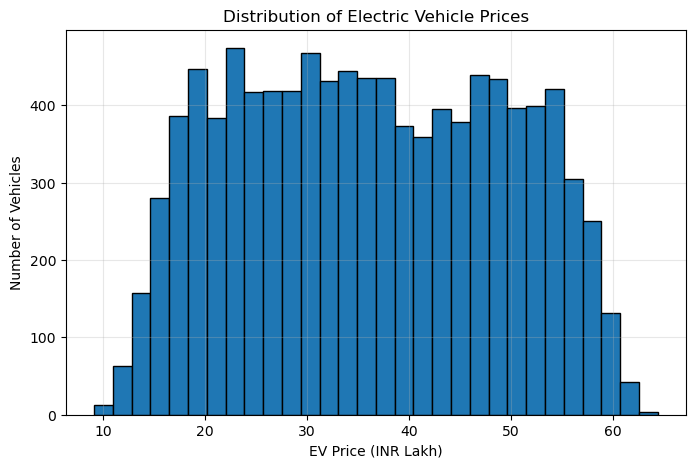

In [25]:

plt.figure(figsize=(8, 5))

plt.hist(df["Price_INR_Lakh"], bins=30, edgecolor="black")

plt.xlabel("EV Price (INR Lakh)")
plt.ylabel("Number of Vehicles")
plt.title("Distribution of Electric Vehicle Prices")

plt.grid(alpha=0.3)
plt.show()

# 6.2 Studying the relationship between battery capacity and price


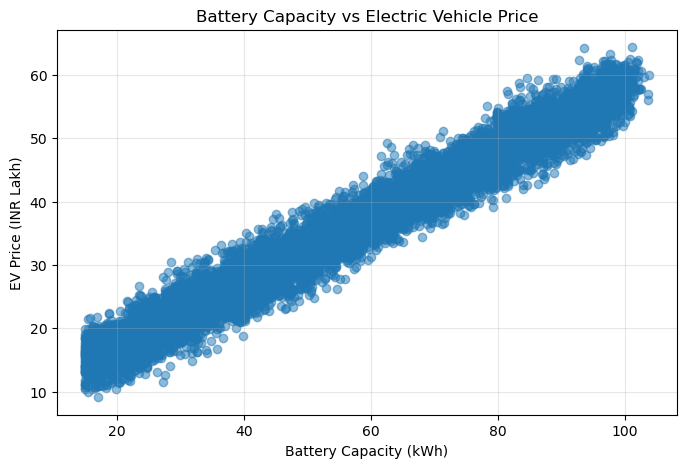

In [26]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Battery_Capacity_kWh"],
    df["Price_INR_Lakh"],
    alpha=0.5
)

plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("EV Price (INR Lakh)")
plt.title("Battery Capacity vs Electric Vehicle Price")

plt.grid(alpha=0.3)
plt.show()

# 6.3 Comparing driving range with EV price


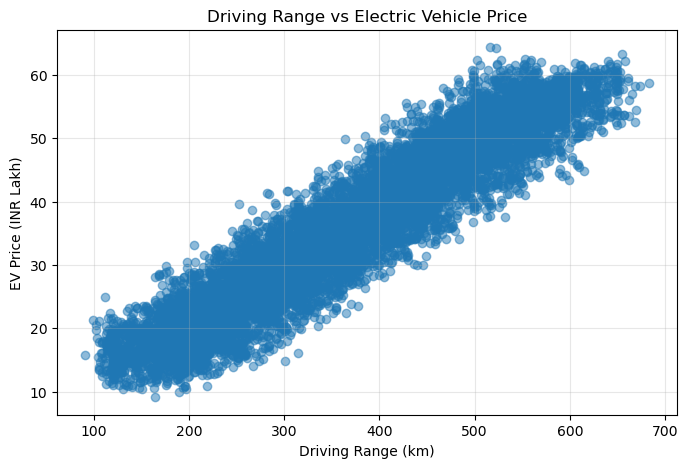

In [27]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Range_km"],
    df["Price_INR_Lakh"],
    alpha=0.5
)

plt.xlabel("Driving Range (km)")
plt.ylabel("EV Price (INR Lakh)")
plt.title("Driving Range vs Electric Vehicle Price")

plt.grid(alpha=0.3)
plt.show()

# 6.4 Visualising correlations among numerical features


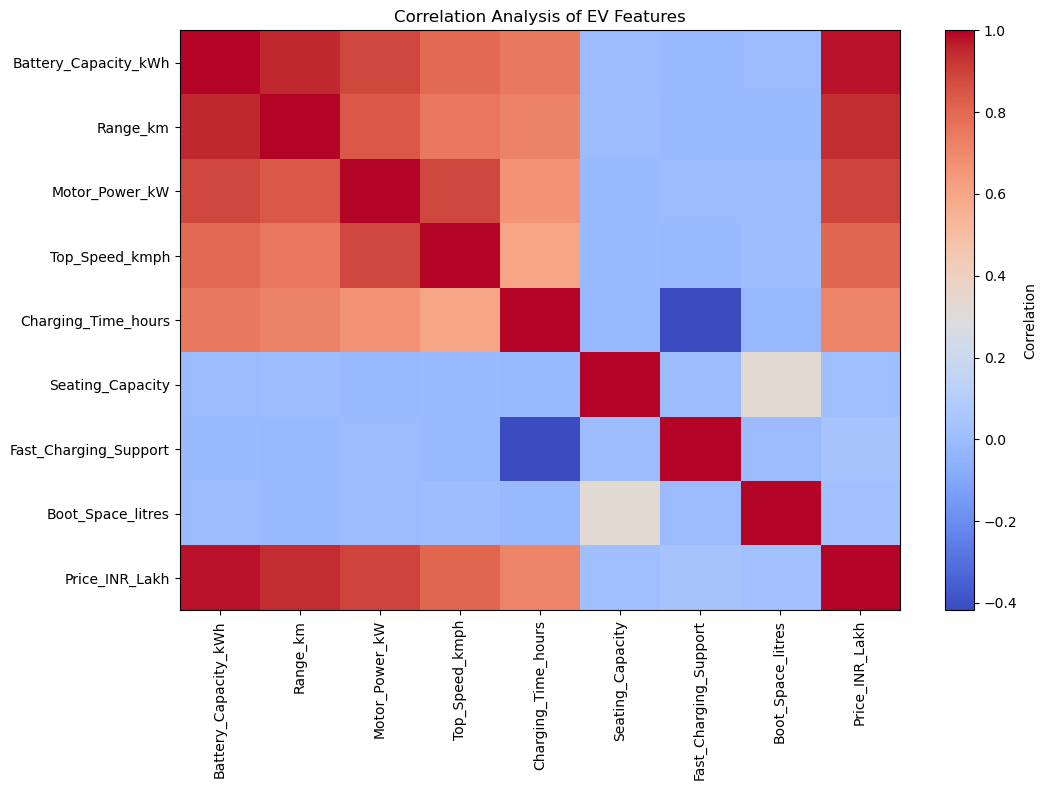

In [28]:

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Analysis of EV Features")
plt.tight_layout()
plt.show()